In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.feature_selection import SelectFromModel

from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [70]:
df= pd.read_csv("Loan_Default.csv")

In [72]:
df.head()

,ID,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,business_or_commercial,loan_amount,rate_of_interest,...,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Status,dtir1
0,24890,cf,Sex Not Available,nopre,type1,p1,l1,nob/c,116500,NaN,...,1740.0,EXP,758,CIB,25-34,to_inst,98.728814,south,1,45.0
1,24891,cf,Male,nopre,type2,p1,l1,b/c,206500,NaN,...,4980.0,EQUI,552,EXP,55-64,to_inst,NaN,North,1,NaN
2,24892,cf,Male,pre,type1,p1,l1,nob/c,406500,4.56,...,9480.0,EXP,834,CIB,35-44,to_inst,80.019685,south,0,46.0
3,24893,cf,Male,nopre,type1,p4,l1,nob/c,456500,4.25,...,11880.0,EXP,587,CIB,45-54,not_inst,69.376900,North,0,42.0
4,24894,cf,Joint,pre,type1,p1,l1,nob/c,696500,4.00,...,10440.0,CRIF,602,EXP,25-34,not_inst,91.886544,North,0,39.0


In [74]:
df.shape

(148670, 28)

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 28 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   loan_limit                 145326 non-null  object 
 2   Gender                     148670 non-null  object 
 3   approv_in_adv              147762 non-null  object 
 4   loan_type                  148670 non-null  object 
 5   loan_purpose               148536 non-null  object 
 6   Credit_Worthiness          148670 non-null  object 
 7   business_or_commercial     148670 non-null  object 
 8   loan_amount                148670 non-null  int64  
 9   rate_of_interest           112231 non-null  float64
 10  Interest_rate_spread       112031 non-null  float64
 11  Upfront_charges            109028 non-null  float64
 12  term                       148629 non-null  float64
 13  Neg_ammortization          14

In [78]:
df['Status'].value_counts()

Status
0    112031
1     36639
Name: count, dtype: int64

In [80]:
# Common reasons to remove column:
# 1. Leaky features that reveal target information (data leakage)
# 2. Highly correlated with another feature (redundant)
# 3. Mostly missing or irrelevant

leaky_cols = [
    'rate_of_interest',          
    'Interest_rate_spread',      
    'Upfront_charges',     
    'Credit_Worthiness',         
    'approv_in_adv'   
]

In [82]:
X = df.drop(columns= leaky_cols + ['ID', 'Status'])
y = df['Status']

In [86]:
print("Columns after removing leakage & ID:\n", X.columns)

Columns after removing leakage & ID:
 Index(['loan_limit', 'Gender', 'loan_type', 'loan_purpose',
       'business_or_commercial', 'loan_amount', 'term', 'Neg_ammortization',
       'interest_only', 'lump_sum_payment', 'property_value', 'occupancy_type',
       'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type',
       'age', 'submission_of_application', 'LTV', 'Region', 'dtir1'],
      dtype='object')


Text(0, 0.5, 'Missing (%)')

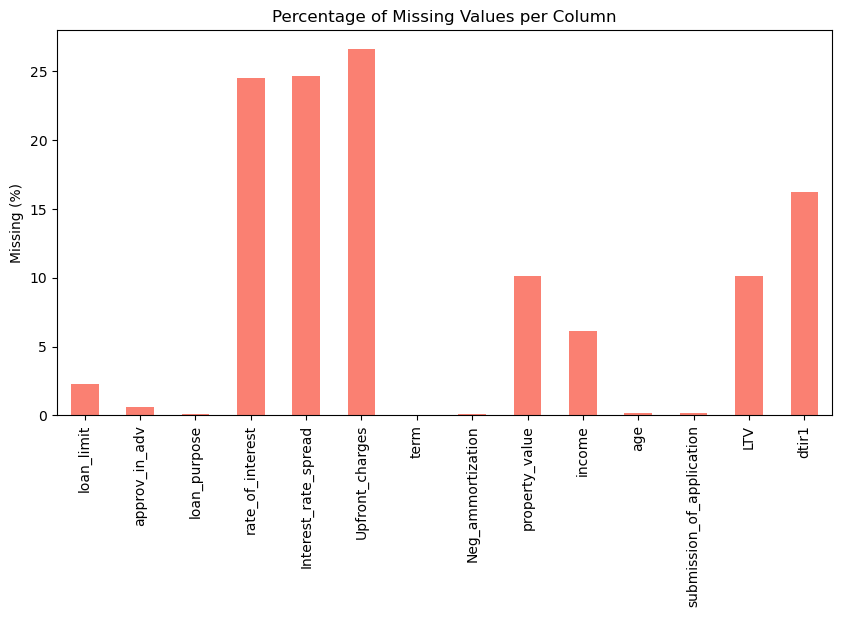

In [144]:
missing_percent = df.isnull().mean() * 100
missing_percent = missing_percent[missing_percent > 0]

plt.figure(figsize=(10,5))
missing_percent.plot(kind='bar', color='salmon')
plt.title("Percentage of Missing Values per Column")
plt.ylabel("Missing (%)")

In [90]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

In [92]:
X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])

In [94]:
for col in cat_cols:
    # Impute missing values
    X[col] = SimpleImputer(strategy='most_frequent').fit_transform(X[[col]]).ravel()
    # Encode to numeric
    X[col] = LabelEncoder().fit_transform(X[col])

<Axes: >

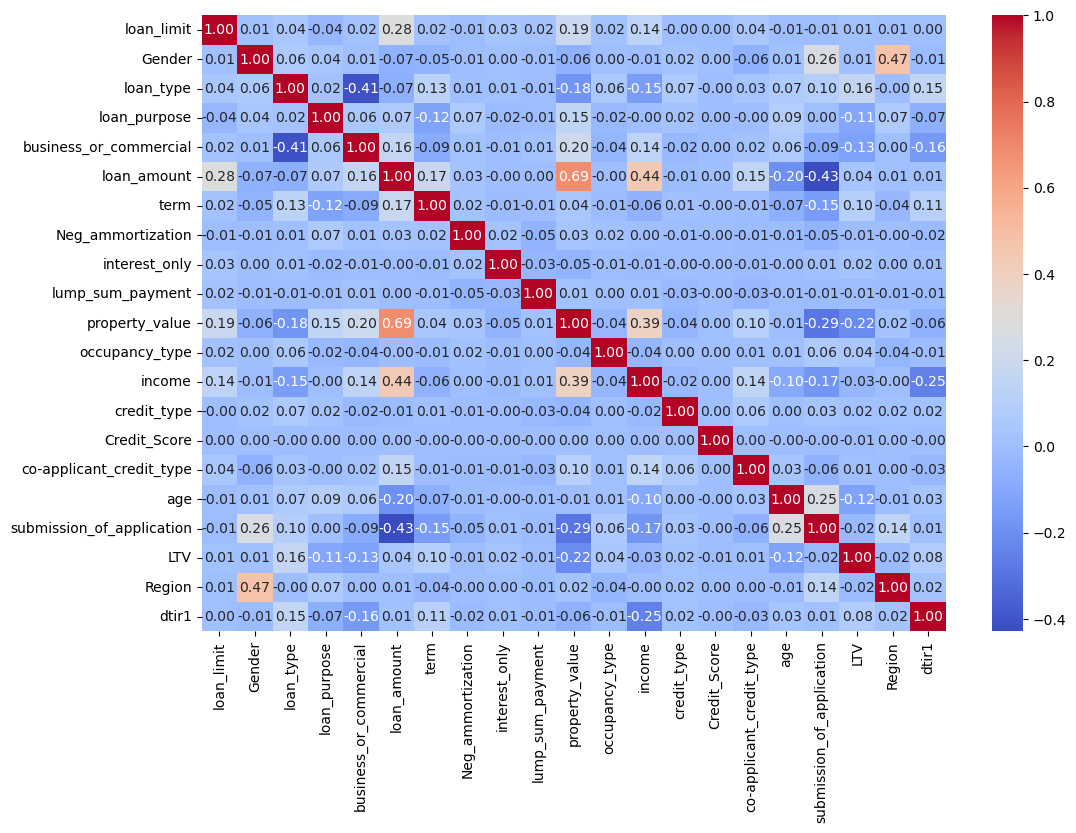

In [104]:
corr_matrix = X.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")

In [106]:
X.isnull().sum()

loan_limit                   0
Gender                       0
loan_type                    0
loan_purpose                 0
business_or_commercial       0
loan_amount                  0
term                         0
Neg_ammortization            0
interest_only                0
lump_sum_payment             0
property_value               0
occupancy_type               0
income                       0
credit_type                  0
Credit_Score                 0
co-applicant_credit_type     0
age                          0
submission_of_application    0
LTV                          0
Region                       0
dtir1                        0
dtype: int64

In [146]:
rf_selector = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_selector.fit(X, y)

sfm = SelectFromModel(rf_selector, threshold='median')  # Keeping features above median
X_selected = sfm.transform(X)
selected_features = X.columns[sfm.get_support()]
print(f"Selected {len(selected_features)} features:\n", selected_features)

Selected 11 features:
 Index(['loan_purpose', 'loan_amount', 'lump_sum_payment', 'property_value',
       'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type',
       'age', 'LTV', 'dtir1'],
      dtype='object')


In [110]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)

In [112]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

In [114]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, C=2.0, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, min_samples_leaf=100, min_samples_split=200,
                                            class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=50,
                                            min_samples_split=100, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
    'Linear SVM': LinearSVC(C=5, class_weight='balanced', max_iter=5000, random_state=42)
}

In [116]:
results = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy of {name}: {acc:.4f}")

    results[name] = {
        'model': model,
        'y_pred': y_pred
    }


Training Logistic Regression...
Accuracy of Logistic Regression: 0.6503

Training Decision Tree...
Accuracy of Decision Tree: 0.8456

Training Random Forest...
Accuracy of Random Forest: 0.8602

Training Linear SVM...
Accuracy of Linear SVM: 0.6464


In [118]:
voting_clf = VotingClassifier(
    estimators=[(name, res['model']) for name, res in results.items()],
    voting='hard'
)

In [120]:
voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('Logistic Regression',
                              LogisticRegression(C=2.0, class_weight='balanced',
                                                 max_iter=1000,
                                                 random_state=42)),
                             ('Decision Tree',
                              DecisionTreeClassifier(class_weight='balanced',
                                                     max_depth=10,
                                                     min_samples_leaf=100,
                                                     min_samples_split=200,
                                                     random_state=42)),
                             ('Random Forest',
                              RandomForestClassifier(class_weight='balanced',
                                                     max_depth=12,
                                                     min_samples_leaf=50,
                                                     min_samples_split=100,
                                                     n_estimators=300,
                                                     n_jobs=-1,
                                                     random_state=42)),
                             ('Linear SVM',
                              LinearSVC(C=5, class_weight='balanced',
                                        max_iter=5000, random_state=42))])

In [121]:
y_pred_voting = voting_clf.predict(X_test)

In [122]:
results['Voting Classifier'] = {'model': voting_clf, 'y_pred': y_pred_voting}

In [123]:
for name, res in results.items():
    print(f"\n{name} Metrics:")
    print(classification_report(y_test, res['y_pred']))
    print("Confusion Matrix:\n", confusion_matrix(y_test, res['y_pred']))


Logistic Regression Metrics:
              precision    recall  f1-score   support

           0       0.86      0.64      0.73     22406
           1       0.38      0.67      0.49      7328

    accuracy                           0.65     29734
   macro avg       0.62      0.66      0.61     29734
weighted avg       0.74      0.65      0.67     29734

Confusion Matrix:
 [[14412  7994]
 [ 2403  4925]]

Decision Tree Metrics:
              precision    recall  f1-score   support

           0       0.89      0.90      0.90     22406
           1       0.69      0.67      0.68      7328

    accuracy                           0.85     29734
   macro avg       0.79      0.79      0.79     29734
weighted avg       0.84      0.85      0.85     29734

Confusion Matrix:
 [[20198  2208]
 [ 2382  4946]]

Random Forest Metrics:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91     22406
           1       0.74      0.67      0.70      7328

    

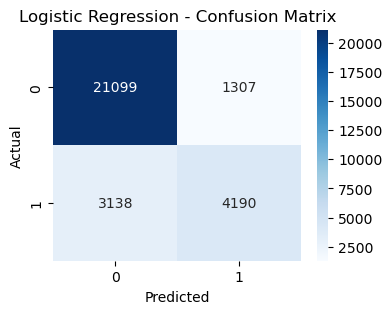

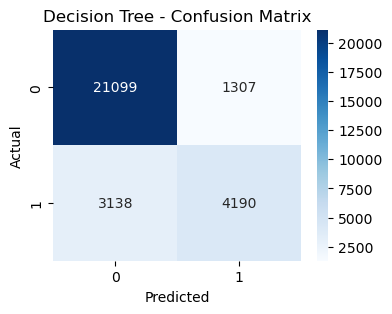

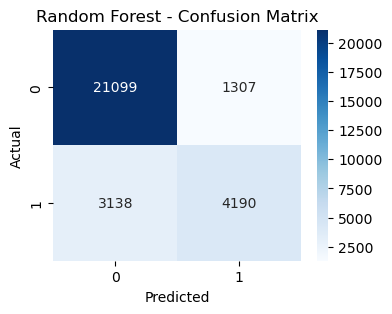

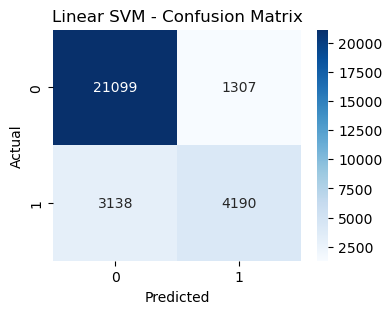

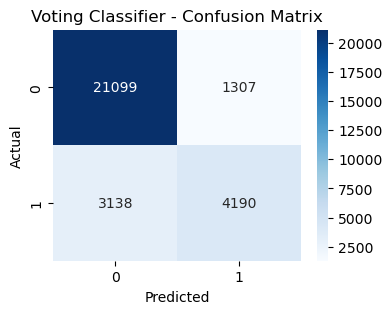

In [152]:
for name, res in results.items():
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

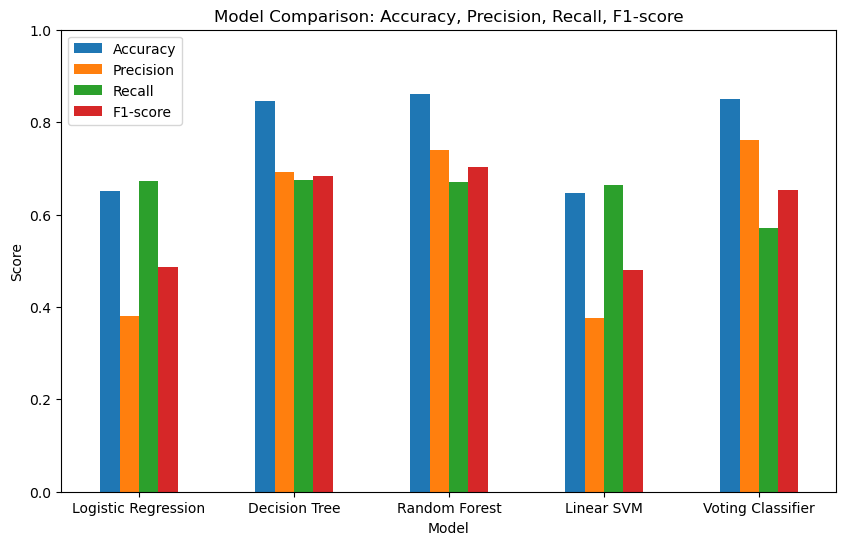

                     Accuracy  Precision    Recall  F1-score
Model                                                       
Logistic Regression  0.650333   0.381221  0.672080  0.486492
Decision Tree        0.845631   0.691361  0.674945  0.683055
Random Forest        0.860194   0.738600  0.669760  0.702498
Linear SVM           0.646398   0.376741  0.664438  0.480841
Voting Classifier    0.850508   0.762234  0.571779  0.653411


In [168]:
metrics_summary = []

for name, res in results.items():
    y_pred = res['y_pred']
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    metrics_summary.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    })

metrics_df = pd.DataFrame(metrics_summary)
metrics_df = metrics_df.set_index('Model')

metrics_df.plot(kind='bar', figsize=(10,6), rot=0)
plt.title("Model Comparison: Accuracy, Precision, Recall, F1-score")
plt.ylabel("Score")
plt.ylim(0,1)
plt.legend()
plt.show()

print(metrics_df)

In [172]:
sample = X_test[:100]
preds = voting_clf.predict(sample)
print("Prediction:", preds)

Prediction: [0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0
 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0]


In [174]:
le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    le_dict[col] = le

features_used = selected_features 

# Function to take user input
def interactive_predict(model, scaler, features, le_dict, df):
    print("Enter applicant data.\n")
    user_data = {}

    for col in features:
        if col in le_dict:  # categorical
            le = le_dict[col]
            options = df[col].dropna().unique().tolist()
            mapping = dict(zip(range(len(options)), options))  # numeric->string
            print(f"{col} options:")
            for k, v in mapping.items():
                print(f"  {k} -> {v}")
            while True:
                val = input(f"Enter the number for {col}: ").strip()
                if val.isdigit() and int(val) in mapping:
                    user_data[col] = int(val)
                    break
                else:
                    print("Invalid input. Please select a number from the list.")
        else:  # numeric
            col_min = df[col].min()
            col_max = df[col].max()
            while True:
                try:
                    val = float(input(f"{col} (numeric, range {col_min}-{col_max}): "))
                    user_data[col] = val
                    break
                except:
                    print("Invalid input. Enter a numeric value.")

    # Convert to DataFrame and scale
    X_input = pd.DataFrame([user_data])[features]
    X_input_scaled = scaler.transform(X_input)

    # Predict
    pred = model.predict(X_input_scaled)[0]
    print("\nPrediction Result:")
    print("Class 0 -> No Default" if pred == 0 else "Class 1 -> Default")


In [182]:
# Run the function
interactive_predict(voting_clf, scaler, selected_features, le_dict, df)

Enter applicant data.

loan_purpose options:
  0 -> p1
  1 -> p4
  2 -> p3
  3 -> p2


Enter the number for loan_purpose:  0
loan_amount (numeric, range 16500-3576500):  16500


lump_sum_payment options:
  0 -> not_lpsm
  1 -> lpsm


Enter the number for lump_sum_payment:  0
property_value (numeric, range 8000.0-16508000.0):  16500000
income (numeric, range 0.0-578580.0):  578580


credit_type options:
  0 -> EXP
  1 -> EQUI
  2 -> CRIF
  3 -> CIB


Enter the number for credit_type:  0
Credit_Score (numeric, range 500-900):  900


co-applicant_credit_type options:
  0 -> CIB
  1 -> EXP


Enter the number for co-applicant_credit_type:  0


age options:
  0 -> 25-34
  1 -> 55-64
  2 -> 35-44
  3 -> 45-54
  4 -> 65-74
  5 -> >74
  6 -> <25


Enter the number for age:  2
LTV (numeric, range 0.967478198-7831.25):  0.97
dtir1 (numeric, range 5.0-61.0):  5



Prediction Result:
Class 0 -> No Default
